In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier  
from sklearn.linear_model import LogisticRegression, LinearRegression 
from sklearn.neighbors import KNeighborsClassifier , KNeighborsRegressor
from sklearn.ensemble import AdaBoostClassifier ,GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score,r2_score  
from tqdm import tqdm

from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore")
import os 
os.chdir('E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets\Cases\Concrete_Strength')

In [11]:
conc = pd.read_csv('Concrete_Data.csv')
conc

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.28
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.18
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.70
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.77


In [12]:
X,y = conc.drop('Strength', axis = 1) , conc['Strength']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state=26)

In [13]:
gbm = GradientBoostingRegressor(random_state = 26)
gbm.fit(X_train, y_train)
y_pred = gbm.predict(X_test) 
r2_score(y_test, y_pred)

0.8997023518625237

In [14]:

learning_rate = np.linspace(0.01,0.9,10)
max_depth = [None,2,3,4]
n_estimator  = [25,50,100]

scores =  []
for l in tqdm(learning_rate):
    for d in max_depth:
        for n in n_estimator:
            
            gbm = GradientBoostingRegressor(random_state = 26, learning_rate=l, max_depth=d, n_estimators=n)
            gbm.fit(X_train, y_train)
            y_pred = gbm.predict(X_test) 

            scores.append([l, d, n ,r2_score(y_test, y_pred) ])
df_scores = pd.DataFrame(scores , columns=['learning_rate','max_depth','n_estimator','score'])
df_scores.sort_values(by='score' , ascending=False)

100%|██████████| 10/10 [00:15<00:00,  1.53s/it]


,learning_rate,max_depth,n_estimator,score
68,0.504444,3.0,100,0.927796
56,0.405556,3.0,100,0.927673
77,0.603333,2.0,100,0.927434
101,0.801111,2.0,100,0.925072
53,0.405556,2.0,100,0.924303
...,...,...,...,...
0,0.010000,NaN,25,0.354160
4,0.010000,2.0,50,0.314529
9,0.010000,4.0,25,0.279623
6,0.010000,3.0,25,0.244498


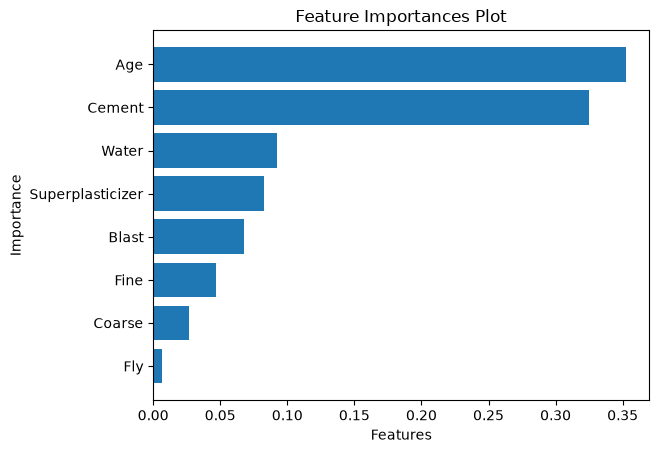

In [15]:
best_tree = GradientBoostingRegressor(random_state=26,learning_rate=0.504444,max_depth=3,n_estimators=100)
best_tree.fit(X, y)
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace=True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances Plot")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.show()